# 02 — Foursquare data cleaning

Foursquare stores POI categories as a hierarchy, e.g.
`Dining and Drinking > Restaurant > Italian Restaurant`.

In this notebook we:
1. load the POIs of one metro area
2. split the category labels into levels
3. keep a **top** category (level 1) and a more detailed **category** (level 2, or level 1 if nothing more detailed exists)
4. look at the categories (tables, bar chart, map)
5. save the cleaned POIs

Change `METRO` to look at another city. The last cell cleans all 50 metros at once.

In [1]:
# ── imports ───────────────────────────────────────────────────────────────────
import json
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt

# ── font sizes ────────────────────────────────────────────────────────────────
FS = 10
FS2 = FS - 2
FS4 = FS - 4

# ── paths ─────────────────────────────────────────────────────────────────────
RAW = "../data/raw/"
PROCESSED = "../data/processed/"

# ── choose a metro (file name without the .parquet ending) ────────────────────
METRO = "foursquare_14460_boston_places"

In [2]:
# ── load ──────────────────────────────────────────────────────────────────────
fs_df = pd.read_parquet(RAW + "POI_US_top50_metros/" + METRO + ".parquet")
print(f"All POIs: {len(fs_df)}")

# ── drop POIs without category information ───────────────────────────────────
fs_df = fs_df[fs_df["fsq_category_labels"].notna()]
print(f"POIs with a category: {len(fs_df)}")

All POIs: 387309
POIs with a category: 358176


In [3]:
# ── clean categories ──────────────────────────────────────────────────────────
# fsq_category_labels is a list of labels, e.g. ["Dining and Drinking > Restaurant > Italian Restaurant"]
# some POIs have more than one label -- we use the first (main) one
def clean_categories(df):
    df = df[df["fsq_category_labels"].notna()].copy()
    df["categories"] = df["fsq_category_labels"].apply(lambda labels: labels[0].split(" > "))
    df["levels"] = df["categories"].apply(len)
    df["top"] = df["categories"].apply(lambda x: x[0])
    df["category"] = df["categories"].apply(lambda x: x[1] if len(x) > 1 else x[0])
    return df

fs_df = clean_categories(fs_df)

print(f"Unique top categories: {fs_df['top'].nunique()}")
print(f"Unique detailed categories: {fs_df['category'].nunique()}")
fs_df[["name", "fsq_category_labels", "top", "category"]].head(10)

Unique top categories: 10
Unique detailed categories: 418


,name,fsq_category_labels,top,category
0,Aidekman Performance Hanger,[Arts and Entertainment > Performing Arts Venue],Arts and Entertainment,Performing Arts Venue
1,Ua Flight 3413,[Travel and Transportation > Transport Hub > A...,Travel and Transportation,Transport Hub
2,James Harold Traynor CPA,[Business and Professional Services > Financia...,Business and Professional Services,Financial Service
3,Medway Garden Center,[Retail > Garden Center],Retail,Garden Center
4,Simon Willard Woods,[Landmarks and Outdoors > Hiking Trail],Landmarks and Outdoors,Hiking Trail
5,Malibu Station Invasion Tour Boston,"[Landmarks and Outdoors > Beach, Arts and Ente...",Landmarks and Outdoors,Beach
6,Team TUFGirl Athletics,[Sports and Recreation],Sports and Recreation,Sports and Recreation
7,NouveauDerm Medspa,[Health and Medicine > Physician > Dermatologist],Health and Medicine,Physician
9,Wedding Tresses Ma/Cape Cod Studio,[Business and Professional Services > Health a...,Business and Professional Services,Health and Beauty Service
10,Namaste Spice,[Dining and Drinking > Restaurant > Indian Res...,Dining and Drinking,Restaurant


In [4]:
# ── most frequent detailed categories ────────────────────────────────────────
fs_df["category"].value_counts().head(20)

category
Restaurant                            24131
Home Improvement Service              21244
Office                                16575
Financial Service                     14761
Education                             14521
Health and Beauty Service             13176
Physician                             10639
Bar                                    9129
Automotive Service                     8505
Fashion Retail                         7065
Real Estate Service                    7027
Transport Hub                          6231
Structure                              5645
Gym and Studio                         5633
Residential Building                   5340
Legal Service                          5130
Construction Supplies Store            5061
Food and Beverage Retail               4825
Spiritual Center                       4694
Business and Professional Services     4249
Name: count, dtype: int64

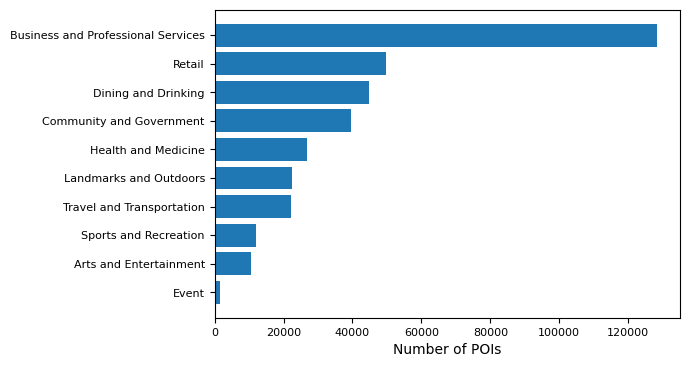

In [5]:
# ── bar chart: number of POIs by top category ────────────────────────────────
counts = fs_df["top"].value_counts().sort_values()

fig, ax = plt.subplots(figsize=(6, 4))
ax.barh(counts.index, counts.values, color="tab:blue")
ax.set_xlabel("Number of POIs", fontsize=FS)
ax.tick_params(labelsize=FS2)

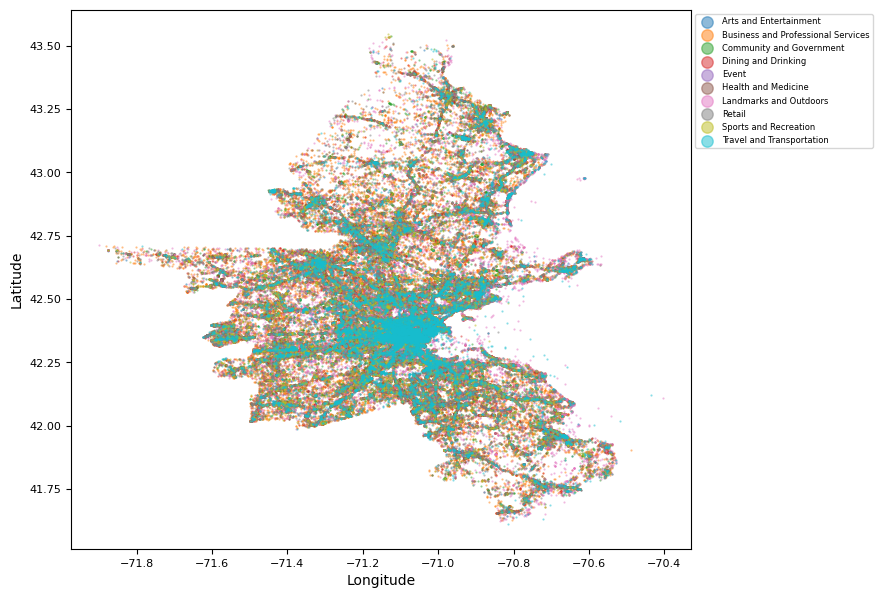

In [6]:
# ── map: POIs colored by top category ────────────────────────────────────────
fig, ax = plt.subplots(figsize=(8, 7))
for top, group in fs_df.groupby("top"):
    ax.scatter(group["longitude"], group["latitude"], s=0.3, alpha=0.5, label=top)

ax.set_xlabel("Longitude", fontsize=FS)
ax.set_ylabel("Latitude", fontsize=FS)
ax.tick_params(labelsize=FS2)
ax.legend(fontsize=FS4, markerscale=15, loc="upper left", bbox_to_anchor=(1, 1))

In [7]:
# ── save cleaned POIs of this metro ───────────────────────────────────────────
cols = ["fsq_place_id", "name", "latitude", "longitude", "cbsacode", "top", "category"]
fs_df[cols].to_parquet(PROCESSED + METRO + "_clean.parquet", index=False)
print(f"Saved: data/processed/{METRO}_clean.parquet  ({len(fs_df)} rows)")

Saved: data/processed/foursquare_14460_boston_places_clean.parquet  (358176 rows)


In [8]:
# ── clean ALL metros and save them in one file ───────────────────────────────
import os

folder = RAW + "POI_US_top50_metros/"
all_metros = []
for file in sorted(os.listdir(folder)):
    df = pd.read_parquet(folder + file)
    df = clean_categories(df)
    all_metros.append(df[cols])

all_metros = pd.concat(all_metros, ignore_index=True)
all_metros.to_parquet(PROCESSED + "foursquare_top50_metros_clean.parquet", index=False)
print(f"Saved: data/processed/foursquare_top50_metros_clean.parquet  ({len(all_metros)} rows)")

Saved: data/processed/foursquare_top50_metros_clean.parquet  (12124376 rows)
